# A Semi-Multiplicative MMM with Terms

In [Rebuilding the Reference MMMs](experimental_mmm_api.ipynb), we used the experimental API to write the same additive models as the stable `MMM` class. Here we change the model itself: media adds demand, while price scales the demand that can become sales. This is a simple semi-multiplicative structure motivated by [issue #3088](https://github.com/pymc-labs/pymc-marketing/issues/3088).

We generate weekly data from a known model, write its equation with terms, fit it and recover its parameters and media effects. We then forecast twelve weeks, compare two price scenarios and jointly optimize media spend and price. The purpose is the model definition, not a new model class: `GAM`, `Data`, `Equation` and the existing terms are enough.

> **Warning:** The experimental API is under active development. This notebook imports it from `pymc_marketing.experimental.terms` and does not change the stable `MMM` class.

## The Model

Let $f_c$ be normalized geometric adstock followed by logistic saturation. The additive demand block and the market multiplier are

$$
A_t = b + \sum_c \beta_c f_c(x_{c,t}), \qquad
M_t = \left(\frac{p_t}{p_{\mathrm{ref}}}\right)^{\gamma_p}.
$$

Weekly sales have a semi-multiplicative mean but additive observation noise:

$$
y_t \sim \operatorname{Normal}(A_t M_t, \sigma).
$$

At the reference price, $M_t=1$ and the mean reduces to the additive model. Price is strictly positive. A positive baseline and positive media amplitudes make $A_t>0$ by construction; we do not apply a hidden transform to a signed additive predictor. Choosing this structure does not force a LogNormal likelihood.

There is **one observed target, `sales`**, and two inputs, media spend and price. The price exponent is a conditional elasticity of expected sales, holding spend fixed. This is an assumption of the simulated model, not a claim that fitting observational data would identify causal effects. Named quantities such as `media_at_reference`, `market_multiplier` and `sales_response` are deterministic components, not additional targets.

## Prepare Notebook

In [1]:
import warnings
from collections.abc import Mapping
from typing import Any

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.xtensor as ptx
import xarray as xr
from IPython.display import display
from pymc_extras.printing import model_table
from pymc_extras.prior import Prior

from pymc_marketing.experimental.terms import GAM, Data, Equation, Problem
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.terms import Named, Parameter, Transform

warnings.filterwarnings("ignore", category=FutureWarning)
az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 4]
plt.rcParams["figure.dpi"] = 70
rng = np.random.default_rng(sum(map(ord, "semi-multiplicative")))

## Data Generating Process

We simulate two media channels and price independently so that their effects can be separated in this example. Each channel sometimes turns off. There are 208 training weeks followed by twelve weeks reserved for a forecast check. The process has no spend before the first simulated week.

We declare the units once: channel spend is divided by a fixed per-channel amount, sales are measured in thousands, and the price reference is 10. These constants are reused for training and forecasting; none is recomputed from future data.

In [2]:
n_train, n_forecast, l_max = 208, 12, 8
n_weeks = n_train + n_forecast
dates = pd.date_range("2020-01-06", periods=n_weeks, freq="W-MON")
channels = ["x1", "x2"]
channel_scale = xr.DataArray(
    [100.0, 80.0], dims="channel", coords={"channel": channels}
)
target_scale = 1_000.0
price_reference = 10.0

true_baseline, true_sigma = 1_000.0, 60.0
true_alpha = np.array([0.4, 0.2])
true_lam = np.array([3.0, 4.0])
true_beta = np.array([700.0, 400.0])
true_price_elasticity = -1.2

spend_scaled = rng.uniform(0.0, 1.0, size=(n_weeks, len(channels)))
spend_scaled *= rng.random(spend_scaled.shape) > 0.2
price = price_reference * rng.uniform(0.8, 1.2, size=n_weeks)

# NumPy computation, independent of the graph we fit below.
adstocked = np.column_stack(
    [
        np.convolve(
            spend_scaled[:, c],
            alpha ** np.arange(l_max) / (alpha ** np.arange(l_max)).sum(),
        )[:n_weeks]
        for c, alpha in enumerate(true_alpha)
    ]
)
true_media_at_reference = true_beta * np.tanh(true_lam * adstocked / 2)
true_additive = true_baseline + true_media_at_reference.sum(axis=1)
true_multiplier = (price / price_reference) ** true_price_elasticity
true_response = true_additive * true_multiplier
true_media_contribution = true_media_at_reference * true_multiplier[:, None]

original = xr.Dataset(
    {
        "spend": (("date", "channel"), spend_scaled * channel_scale.values),
        "price": ("date", price),
        "sales": ("date", true_response + rng.normal(0.0, true_sigma, n_weeks)),
    },
    coords={"date": dates, "channel": channels},
)
scaled = original.assign(
    spend=original["spend"] / channel_scale,
    sales=original["sales"] / target_scale,
)
train = scaled.isel(date=slice(0, n_train))
future = scaled.isel(date=slice(n_train, None)).drop_vars("sales")
print(f"Training weeks: {train.sizes['date']}; forecast weeks: {future.sizes['date']}")
print(f"Price reference: {price_reference}")

Training weeks: 208; forecast weeks: 12
Price reference: 10.0


## Model Specification

The media pipeline is the same as in the reference notebook. Its output is named `media_at_reference`: it is an additive sales effect **at the reference price**, not yet the realized effect under the current price.

We express the price power factor in log space, $\gamma_p\log(p/p_{\mathrm{ref}})$, and exponentiate it. This is exactly $(1+z)^{\gamma_p}$ for a proportional change $z=p/p_{\mathrm{ref}}-1$. `Transform` applies an ordinary named PyTensor operation to a lazy term; `Parameter` declares its coefficient. The illustrative priors below are on the declared model scale, so media amplitudes are in thousands of sales and the price elasticity is dimensionless.

The baseline is a `Prior` directly, with `Named` used only to retain a readable `baseline` output. It creates the free variable `baseline_param` and records its value as `baseline`; it is not an `Intercept` or `Parameter` term.

In [3]:
spend_data = Data("spend")
price_data = Data("price")

media_at_reference = (
    spend_data
    >> GeometricAdstock(l_max=l_max, priors={"alpha": Prior("Beta", alpha=2, beta=5)})
    >> LogisticSaturation(
        priors={
            "beta": Prior("HalfNormal", sigma=0.8),
            "lam": Prior("Gamma", alpha=3, beta=1),
        }
    )
).named("media_at_reference")

baseline = Named("baseline", Prior("Gamma", mu=1.0, sigma=0.5))
additive = (baseline + media_at_reference.sum("channel")).named("additive_block")

price_elasticity = Parameter("price_elasticity", prior=Prior("Normal", mu=0, sigma=1))
price_log_factor = (
    price_elasticity
    * Transform(price_data * (1.0 / price_reference), func=ptx.math.log)
).named("price_log_factor")
market_multiplier = Transform(price_log_factor, func=ptx.math.exp).named(
    "market_multiplier"
)

sales_response = (additive * market_multiplier).named("sales_response")

sales = Equation(
    name="y",
    observed="sales",
    mu=sales_response,
    likelihood=Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
)
gam = GAM(sales)
gam.build_model(train)
model_table(gam.model)

             Variable  Expression                                                           Dimensions             
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
              spend =  Data                                                                 date[208] × channel[2] 
              price =  Data                                                                 date[208]              
                                                                                                                   
     baseline_param ~  Gamma(<constant>, <constant>)                                                               
      adstock_alpha ~  Beta(2, 5)                                                           channel[2]             
     saturation_lam ~  Gamma(3, <constant>)                                                 channel[2]             
    saturation_beta ~  HalfNormal(0, 0.8)                                                   channel[2]             
   price_elasticity ~  Normal(0, 1)                                                                                
            y_sigma ~  HalfNormal(0, 0.2)                                                                          
                                                                                            Parameter count = 9    
                                                                                                                   
           baseline =  f(baseline_param)                                                                           
 media_at_reference =  f(saturation_beta, saturation_lam, adstock_alpha)                    date[208] × channel[2] 
     additive_block =  f(baseline_param, saturation_beta, saturation_lam, adstock_alpha)    date[208]              
   price_log_factor =  f(price_elasticity)                                                  date[208]              
  market_multiplier =  f(price_elasticity)                                                  date[208]              
     sales_response =  f(price_elasticity, baseline_param, saturation_beta,                 date[208]              
                       saturation_lam, adstock_alpha)                                                              
                                                                                                                   
                  y ~  Normal(f(price_elasticity, baseline_param, saturation_beta,          date[208]              
                       saturation_lam, adstock_alpha), y_sigma)

`GAM` builds the terms reachable from its equations. We compute market-scaled media contributions from the named media and multiplier quantities when reporting below; no additional observed equation is needed.

The important model change is `mu=additive * market_multiplier`. There is no `composition` argument or link flag, and the likelihood remains an independent choice. The positive Gamma baseline and HalfNormal media amplitudes guarantee a positive response for positive price, although the Normal likelihood still allows negative noisy observations.

### Check the Equation at the Generating Parameters

Before fitting, we replace the free parameters by the known values and compare the graph against the independent NumPy calculation. This checks the adstock normalization, saturation, references, scaling and multiplication together, not just the shapes of the outputs.

In [4]:
truth_model = pm.do(
    gam.model,
    {
        "baseline_param": true_baseline / target_scale,
        "adstock_alpha": ptx.as_xtensor(true_alpha, dims=("channel",)),
        "saturation_lam": ptx.as_xtensor(true_lam, dims=("channel",)),
        "saturation_beta": ptx.as_xtensor(true_beta / target_scale, dims=("channel",)),
        "price_elasticity": true_price_elasticity,
    },
)
graph_additive, graph_multiplier, graph_response = pm.draw(
    [
        truth_model[name]
        for name in ("additive_block", "market_multiplier", "sales_response")
    ],
    random_seed=42,
)
np.testing.assert_allclose(
    graph_additive * target_scale, true_additive[:n_train], rtol=1e-12
)
np.testing.assert_allclose(graph_multiplier, true_multiplier[:n_train], rtol=1e-12)
np.testing.assert_allclose(
    graph_response * target_scale, true_response[:n_train], rtol=1e-12
)
print("Graph and NumPy agree at the generating parameters (rtol=1e-12).")

Graph and NumPy agree at the generating parameters (rtol=1e-12).


## Prior Predictive Check

We inspect the implied sales range before fitting. These are noisy sales draws, not just the positive mean. The priors are deliberately broader than the generating values; this is a check of units and plausible magnitude rather than a claim that the priors were learned from the simulated truth.

In [5]:
prior = gam.sample_prior_predictive(train, draws=500, var_names=["y"], random_seed=11)
prior_sales = prior["prior_predictive"]["y"] * target_scale
pd.DataFrame(
    {
        "prior predictive sales": np.quantile(prior_sales.values, [0.03, 0.5, 0.97]),
        "observed training sales": np.quantile(
            original["sales"][:n_train].values, [0.03, 0.5, 0.97]
        ),
    },
    index=["3%", "median", "97%"],
).round(1)

Sampling: [adstock_alpha, baseline_param, price_elasticity, saturation_beta, saturation_lam, y, y_sigma]


,prior predictive sales,observed training sales
3%,502.3,1068.9
median,1476.7,1606.8
97%,3202.2,2271.8


## Model Fitting

We fit all 208 training weeks using four chains. The twelve future outcomes are not supplied to the model. The table reports divergences, the largest parameter R-hat and the smallest bulk effective sample size; the parameter summary below retains the individual diagnostics.

In [6]:
idata = gam.fit(
    train,
    chains=4,
    tune=1_500,
    draws=1_000,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=21,
    progressbar=False,
)
parameter_names = [
    "baseline",
    "adstock_alpha",
    "saturation_beta",
    "saturation_lam",
    "price_elasticity",
    "y_sigma",
]
parameter_summary = az.summary(idata, var_names=parameter_names, round_to=3)
diagnostics = pd.Series(
    {
        "posterior draws": idata["posterior"].sizes["chain"]
        * idata["posterior"].sizes["draw"],
        "divergences": int(idata["sample_stats"]["diverging"].sum()),
        "max R-hat": parameter_summary["r_hat"].max(),
        "min bulk ESS": parameter_summary["ess_bulk"].min(),
    },
    name="sampling diagnostics",
)
display(diagnostics.to_frame())
parameter_summary

NUTS[nutpie]: [baseline_param, adstock_alpha, saturation_lam, saturation_beta, price_elasticity, y_sigma]


,sampling diagnostics
posterior draws,4000.000
divergences,0.000
max R-hat,1.003
min bulk ESS,1212.536


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
baseline,0.988,0.018,0.959,1.015,1668.949,1760.904,1.003,0.000,0.000
adstock_alpha[x1],0.395,0.016,0.369,0.420,2916.044,2699.092,1.000,0.000,0.000
adstock_alpha[x2],0.186,0.025,0.145,0.227,2657.220,2840.828,1.002,0.000,0.000
saturation_beta[x1],0.702,0.030,0.657,0.751,1233.783,1724.045,1.002,0.001,0.001
saturation_beta[x2],0.392,0.017,0.365,0.421,1991.142,2311.996,1.002,0.000,0.000
saturation_lam[x1],3.236,0.249,2.845,3.638,1212.536,1551.598,1.003,0.007,0.005
saturation_lam[x2],4.148,0.341,3.613,4.692,2063.959,2289.399,1.002,0.008,0.005
price_elasticity,-1.211,0.018,-1.240,-1.183,5089.092,2691.188,1.001,0.000,0.000
y_sigma,0.052,0.003,0.048,0.057,5578.700,3233.471,1.000,0.000,0.000


### Parameter Recovery

We compare the posterior with the values used to generate the data. This table converts the baseline, media amplitudes and noise back into sales units; adstock, saturation shape and elasticities retain their own dimensionless scales. Intervals are equal-tailed 94% posterior intervals, not Monte Carlo error bars. Finite-sample recovery is not guaranteed for every parameter, especially the correlated saturation amplitude and shape.

In [7]:
posterior = idata["posterior"].to_dataset()
recovery_rows = []
for name, truth, scale in [
    ("baseline", true_baseline, target_scale),
    ("adstock_alpha", true_alpha, 1.0),
    ("saturation_beta", true_beta, target_scale),
    ("saturation_lam", true_lam, 1.0),
    ("price_elasticity", true_price_elasticity, 1.0),
    ("y_sigma", true_sigma, target_scale),
]:
    values = posterior[name] * scale
    labels = channels if "channel" in values.dims else [None]
    truths = np.atleast_1d(truth)
    for i, channel in enumerate(labels):
        samples = values.sel(channel=channel) if channel is not None else values
        lower, upper = np.quantile(samples.values, [0.03, 0.97])
        recovery_rows.append(
            {
                "parameter": f"{name}[{channel}]" if channel is not None else name,
                "true": truths[i],
                "posterior mean": samples.mean().item(),
                "3%": lower,
                "97%": upper,
            }
        )
recovery = pd.DataFrame(recovery_rows).set_index("parameter")
recovery.round(3)

,true,posterior mean,3%,97%
parameter,,,,
baseline,1000.0,987.538,953.712,1020.519
adstock_alpha[x1],0.4,0.395,0.364,0.425
adstock_alpha[x2],0.2,0.186,0.138,0.234
saturation_beta[x1],700.0,702.305,649.667,762.243
saturation_beta[x2],400.0,392.001,360.890,426.062
saturation_lam[x1],3.0,3.236,2.769,3.705
saturation_lam[x2],4.0,4.148,3.527,4.802
price_elasticity,-1.2,-1.211,-1.245,-1.178
y_sigma,60.0,52.261,47.599,57.423


The diagnostic and recovery tables report this run's sampling quality and how precisely the price elasticity, baseline and media parameters are recovered. These are separate checks: a close fit to sales alone does not guarantee that every parameter is well identified.

Saturation amplitude and shape can compensate for each other, so we also inspect the recovered media effects rather than judging the fit only by individual parameter means.

## Posterior Predictive Check

For the training dates we set `include_last_observations=False`: the generating process started with no earlier spend, and prepending the end of training would create the wrong history. The band describes noisy sales draws. The dashed line is the known expected response, which was not supplied as an observation.

Sampling: [y]


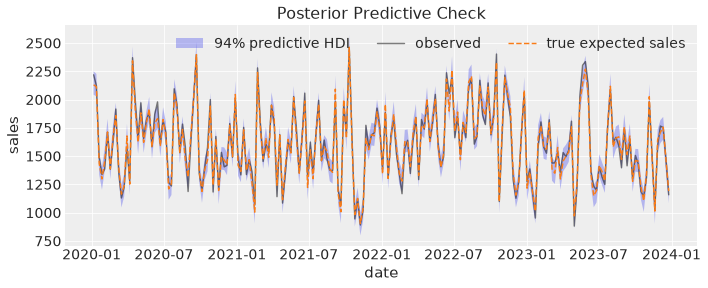

In [8]:
in_sample = gam.sample_posterior_predictive(
    train,
    var_names=[
        "y",
        "sales_response",
        "media_at_reference",
        "market_multiplier",
        "additive_block",
        "baseline",
    ],
    include_last_observations=False,
    random_seed=31,
    progressbar=False,
)
predicted_sales = in_sample["y"] * target_scale
hdi = az.hdi(predicted_sales, prob=0.94)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.fill_between(
    train["date"],
    hdi.sel(ci_bound="lower"),
    hdi.sel(ci_bound="upper"),
    alpha=0.3,
    label="94% predictive HDI",
)
ax.plot(
    train["date"],
    original["sales"][:n_train],
    color="black",
    alpha=0.5,
    label="observed",
)
ax.plot(
    train["date"],
    true_response[:n_train],
    color="C1",
    linestyle="--",
    label="true expected sales",
)
ax.set(title="Posterior Predictive Check", xlabel="date", ylabel="sales")
ax.legend(ncol=3)
plt.show()

## Media Effects under Market Conditions

For this model, removing channel $c$ changes expected sales by $\beta_c f_c(x_{c,t})M_t$: the multiplier does not depend on spend. We multiply the reference media term by the current multiplier **before** summing over dates. These media removal effects plus the market-scaled baseline reconcile to expected sales per draw and week.

The price multiplier scales both the baseline and media. This channel decomposition does not assign price a separate additive share; adding a price-removal effect to it would double count interactions.

Market-scaled baseline and media reconcile to expected sales per draw and week.


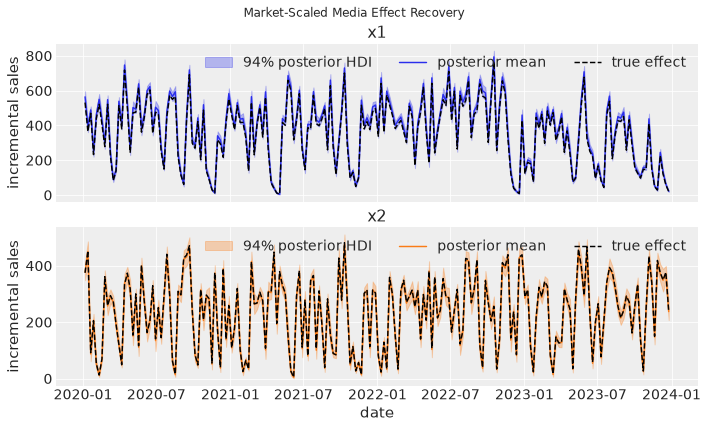

In [9]:
media_contribution = (
    in_sample["media_at_reference"] * in_sample["market_multiplier"] * target_scale
)
scaled_baseline = in_sample["baseline"] * in_sample["market_multiplier"] * target_scale
np.testing.assert_allclose(
    scaled_baseline + media_contribution.sum("channel"),
    in_sample["sales_response"] * target_scale,
    rtol=1e-12,
)
print("Market-scaled baseline and media reconcile to expected sales per draw and week.")

fig, axes = plt.subplots(nrows=2, figsize=(10, 6), sharex=True, layout="constrained")
for i, (channel, ax) in enumerate(zip(channels, axes, strict=True)):
    effect = media_contribution.sel(channel=channel)
    hdi = az.hdi(effect, prob=0.94)
    ax.fill_between(
        train["date"],
        hdi.sel(ci_bound="lower"),
        hdi.sel(ci_bound="upper"),
        color=f"C{i}",
        alpha=0.3,
        label="94% posterior HDI",
    )
    ax.plot(
        train["date"],
        effect.mean(("chain", "draw")),
        color=f"C{i}",
        label="posterior mean",
    )
    ax.plot(
        train["date"],
        true_media_contribution[:n_train, i],
        color="black",
        linestyle="--",
        label="true effect",
    )
    ax.set(title=channel, ylabel="incremental sales")
    ax.legend(ncol=3)
axes[-1].set_xlabel("date")
fig.suptitle("Market-Scaled Media Effect Recovery")
plt.show()

### The Reference Price Recovers the Additive Model

We can ask the fitted model for the same spend at the reference price. This is an in-sample what-if, so again there is no prepended history. Every draw must have a unit market multiplier and a response equal to its additive block.

In [10]:
neutral_inputs = train.drop_vars("sales").assign(
    price=xr.full_like(train["price"], price_reference),
)
neutral = gam.sample_posterior_predictive(
    neutral_inputs,
    var_names=["market_multiplier", "additive_block", "sales_response"],
    include_last_observations=False,
    random_seed=41,
    progressbar=False,
)
np.testing.assert_allclose(neutral["market_multiplier"], 1.0, atol=1e-12)
np.testing.assert_allclose(
    neutral["sales_response"], neutral["additive_block"], rtol=1e-12
)
print("At the reference price, M = 1 and expected sales = A in every draw.")

Sampling: []


At the reference price, M = 1 and expected sales = A in every draw.


## Forecast and a Price Scenario

The next twelve weeks follow training immediately. Here `include_last_observations=True` carries the last seven training weeks into adstock and drops those history rows from the result. We supply future spend and price explicitly; the reference constants and posterior parameters stay fixed.

The forecast is conditional on the simulated future spend and price. A second scenario lowers each future price by 10%, holding spend fixed. We compare **expected sales**, not independent noisy predictive draws. For the chosen Normal likelihood, `sales_response` is the conditional mean.

In [11]:
forecast = gam.sample_posterior_predictive(
    future,
    var_names=["y", "sales_response"],
    include_last_observations=True,
    random_seed=51,
    progressbar=False,
)
lower_price = gam.sample_posterior_predictive(
    future.assign(price=future["price"] * 0.9),
    var_names=["sales_response"],
    include_last_observations=True,
    random_seed=51,
    progressbar=False,
)
# Check the conditional elasticity identity on paired posterior draws.
np.testing.assert_allclose(
    lower_price["sales_response"] / forecast["sales_response"],
    (0.9 ** posterior["price_elasticity"]).broadcast_like(forecast["sales_response"]),
    rtol=1e-12,
)
forecast_draws = forecast["y"] * target_scale
scenario_gain = (lower_price["sales_response"] - forecast["sales_response"]).sum(
    "date"
) * target_scale
relative_gain = scenario_gain / (forecast["sales_response"].sum("date") * target_scale)
forecast_mean = forecast["sales_response"].mean(("chain", "draw")) * target_scale
forecast_metrics = pd.Series(
    {
        "RMSE against held-out sales": float(
            np.sqrt(((forecast_mean - original["sales"][n_train:]) ** 2).mean())
        ),
        "RMSE against true expected sales": float(
            np.sqrt(((forecast_mean - true_response[n_train:]) ** 2).mean())
        ),
        "mean expected-sales gain (%)": 100 * relative_gain.mean().item(),
        "gain 3% (%)": 100 * np.quantile(relative_gain.values, 0.03),
        "gain 97% (%)": 100 * np.quantile(relative_gain.values, 0.97),
        "P(expected-sales gain > 0)": (scenario_gain > 0).mean().item(),
        "true expected-sales gain (%)": 100 * (0.9**true_price_elasticity - 1),
    },
    name="forecast and price scenario",
)
forecast_metrics.to_frame().round(3)

Sampling: [y]


Sampling: []


,forecast and price scenario
RMSE against held-out sales,46.277
RMSE against true expected sales,9.708
mean expected-sales gain (%),13.613
gain 3% (%),13.216
gain 97% (%),14.013
P(expected-sales gain > 0),1.000
true expected-sales gain (%),13.477


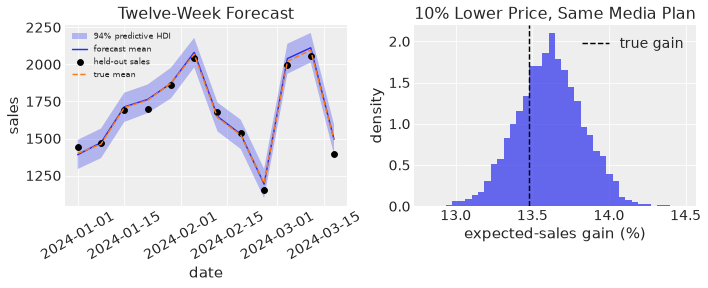

In [12]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 4), layout="constrained")
hdi = az.hdi(forecast_draws, prob=0.94)
axes[0].fill_between(
    future["date"],
    hdi.sel(ci_bound="lower"),
    hdi.sel(ci_bound="upper"),
    alpha=0.3,
    label="94% predictive HDI",
)
axes[0].plot(future["date"], forecast_mean, label="forecast mean")
axes[0].plot(
    future["date"],
    original["sales"][n_train:],
    "o",
    color="black",
    label="held-out sales",
)
axes[0].plot(
    future["date"],
    true_response[n_train:],
    linestyle="--",
    color="C1",
    label="true mean",
)
axes[0].set(title="Twelve-Week Forecast", xlabel="date", ylabel="sales")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
axes[1].hist(100 * relative_gain.values.ravel(), bins=40, density=True, alpha=0.7)
axes[1].axvline(
    100 * (0.9**true_price_elasticity - 1),
    color="black",
    linestyle="--",
    label="true gain",
)
axes[1].set(
    title="10% Lower Price, Same Media Plan",
    xlabel="expected-sales gain (%)",
    ylabel="density",
)
axes[1].legend()
plt.show()

The table compares the forecast with both the held-out noisy sales and the known expected response. The price-scenario interval reflects uncertainty in the elasticity; the generating price elasticity gives a known expected-sales gain for comparison.

The price comparison is a conditional model scenario, not a recommendation to discount: it reports sales, not revenue or profit, and does not include changes in buying behavior beyond the declared elasticity. In real data, causal interpretation would require an identification argument. The paired-draw identity above also checks that the scenario did not accidentally change media history, reference levels or posterior parameters.

## Jointly Optimize Media and Price

We optimize **media effect times the price multiplier**, not total sales, revenue or profit:

$$
\max_{\mathrm{spend},\,p}\;
\mathbb{E}_{\theta\mid y}\!\left[
    \sum_{t,c}\beta_c f_c(\mathrm{spend}_{c,t})\,M_t(p_t;\theta)
\right]
\quad\text{subject to}\quad
\sum_{t,c}\mathrm{spend}_{c,t}\le B.
$$

The selected term is `media_at_reference * market_multiplier`, a deterministic combination of the fitted terms. It measures the expected sales removed by setting all media spend to zero **at the same price**. It excludes the baseline, and it does not introduce another observed target or any cost assumptions.

The planning policy is explicit, just as in the additive notebook:

- Plan **8 weeks**, followed by `l_max - 1` weeks with **zero media spend** to score all carryover from the plan.
- Spend the same amount per channel each planned week and choose **one price for all planned weeks**.
- Set a **maximum** total media budget from business as usual: each channel's historical average weekly spend repeated over the plan. The inequality allows underspending; it does not require the budget to be exhausted.
- Bound each channel by its training maximum and price by the observed training range. Fix tail price at 10 so carryover is valued under an explicit price scenario.
- Start with **no historical carryover**. Business as usual and the optimized plan use exactly the same assumption and scoring window.

There are exactly two inputs: `Data("spend")` and `Data("price")`. `Problem` infers them from the selected terms; its `decisions` template contains only the eight planned weeks. The fixed tail is separate data: zero spend and positive reference price. The model uses scaled spend and sales, so the callbacks convert spend back to currency for the budget and the media effect back to sales units for the objective.

In [13]:
plan_weeks = 8
carryover_weeks = l_max - 1
planning_dates = pd.date_range(
    start=train["date"].values[-1], periods=1 + plan_weeks, freq="W-MON"
)[1:]
tail_dates = pd.date_range(
    start=planning_dates[-1], periods=1 + carryover_weeks, freq="W-MON"
)[1:]
weekly_spend = train["spend"].mean("date")
budget = float((weekly_spend * channel_scale).sum()) * plan_weeks
max_spend = train["spend"].max("date")
min_price = float(train["price"].min())
max_price = float(train["price"].max())
fixed_tail = xr.Dataset(
    {
        "spend": xr.zeros_like(weekly_spend.expand_dims(date=tail_dates)).transpose(
            "date", "channel"
        ),
        "price": xr.DataArray(
            np.full(carryover_weeks, price_reference),
            dims="date",
            coords={"date": tail_dates},
        ),
    }
)

print(f"Maximum media budget for {plan_weeks} planned weeks: {budget:.2f}")
print(
    f"Planned price bounds: {float(train['price'].min()):.2f} "
    f"to {float(train['price'].max()):.2f}; tail price: {price_reference:.2f}"
)

Maximum media budget for 8 planned weeks: 588.92
Planned price bounds: 8.01 to 11.99; tail price: 10.00


`u` contains only the symbolic decisions, while `evaluate(u)["media_effect"]` retains the fitted joint posterior draws on a `sample` dimension and includes the fixed carryover tail. We sum the selected effect over all scored dates and channels, then average over those draws.

The budget callback reads a declared parameter and returns **budget minus spend**, which must be nonnegative for an `"ineq"` constraint. The equality callbacks tie the decided weeks to the first week; the tail is not a decision. `Problem` binds the fitted terms and compiles these callbacks once, before any solve.

In [14]:
def expected_media_effect(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Maximize posterior expected media effect in sales units."""
    effect = evaluate(u)["media_effect"] * target_scale
    return effect.sum("date").sum("channel").mean("sample")


def remaining_budget(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Return the unspent media budget in original currency."""
    spend = u["spend"] * evaluate.constant(channel_scale)
    return evaluate.parameter("budget") - spend.sum("date").sum("channel")


def same_weekly_spend(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Tie each planned week's channel spend to the first week's spend."""
    return u["spend"] - u["spend"].isel(date=0)


def same_weekly_price(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Choose one price for the planned weeks, not for the fixed-price tail."""
    return u["price"] - u["price"].isel(date=0)


problem = Problem(
    model=gam,
    terms={"media_effect": media_at_reference * market_multiplier},
    dates=planning_dates,
    objective=expected_media_effect,
    bounds={
        "spend": (0.0, max_spend),
        "price": (min_price, max_price),
    },
    constraints=[
        {"type": "ineq", "fun": remaining_budget},
        {"type": "eq", "fun": same_weekly_spend},
        {"type": "eq", "fun": same_weekly_price},
    ],
    parameters={"budget": budget},
    carryover=fixed_tail,
    # No history: both plans start with zero pre-plan media carryover.
)
display(problem.decisions)

<xarray.Dataset> Size: 272B
Dimensions:  (date: 8, channel: 2)
Coordinates:
  * date     (date) datetime64[us] 64B 2024-01-01 2024-01-08 ... 2024-02-19
  * channel  (channel) <U2 16B 'x1' 'x2'
Data variables:
    price    (date) float64 64B nan nan nan nan nan nan nan nan
    spend    (date, channel) float64 128B nan nan nan nan ... nan nan nan nan

### Evaluate a Baseline, Then Solve

`evaluate` scores a concrete plan without optimizing it. `solve` is the explicit optimizer run and requires a starting plan, `x0`; constructing `Problem` does not choose or solve a plan. Both calls reuse the same fitted graph and fixed tail.

In [15]:
business_as_usual = problem.decisions.copy()
business_as_usual["spend"] = weekly_spend.broadcast_like(problem.decisions["spend"])
business_as_usual["price"] = xr.full_like(problem.decisions["price"], price_reference)
bau_draws = problem.evaluate(business_as_usual)
optimized_plan = problem.solve(x0=business_as_usual)
optimized_draws = problem.evaluate(optimized_plan.allocation)

if not (optimized_plan.scipy.success and optimized_plan.feasible):
    raise RuntimeError(f"Optimization failed: {optimized_plan.scipy.message}")

allocation = optimized_plan.allocation
optimized_spend = allocation["spend"] * channel_scale
budget_slack = budget - float(optimized_spend.sum())
np.testing.assert_array_less(-1e-6, budget_slack)
for name in ("spend", "price"):
    planned_values = allocation[name]
    np.testing.assert_allclose(
        planned_values,
        planned_values.isel(date=0).broadcast_like(planned_values),
        atol=1e-7,
        rtol=1e-8,
    )

display(
    pd.Series(
        {
            "SciPy success": optimized_plan.scipy.success,
            "independently feasible": optimized_plan.feasible,
            "remaining budget (currency)": float(optimized_plan.constraints[0]),
            "maximum scaled bound violation": optimized_plan.max_bound_violation,
            "maximum scaled constraint violation": optimized_plan.max_constraint_violation,
        },
        name="solver checks",
    ).to_frame()
)
weekly_decisions = pd.DataFrame(
    {
        "business as usual": [
            *(weekly_spend * channel_scale).values,
            price_reference,
        ],
        "optimized": [
            *optimized_spend.isel(date=0).values,
            float(allocation["price"].isel(date=0)),
        ],
    },
    index=[*(f"weekly spend: {channel}" for channel in channels), "price per unit"],
)
weekly_decisions.round(3)

,solver checks
SciPy success,True
independently feasible,True
remaining budget (currency),-0.0
maximum scaled bound violation,0.0
maximum scaled constraint violation,0.0


,business as usual,optimized
weekly spend: x1,40.606,48.609
weekly spend: x2,33.009,25.006
price per unit,10.000,8.006


### Evaluate the Joint Plan on Paired Posterior Draws

Business as usual and the optimized plan are scored with `problem.evaluate`, preserving the same paired posterior draws, no training carryover and the same fixed tail. This evaluation must reproduce the optimizer's reported objective.

As an independent check, we append the fixed tail to each concrete plan and call `sample_posterior_predictive`. We also predict sales with media set to zero while retaining that plan's price. The difference from the plan's expected sales must equal the selected media effect in every draw and week. This proves that the objective excludes the baseline.

In [16]:
def check_media_effect(plan: xr.Dataset, effect: xr.DataArray) -> None:
    """Check the selected effect against independent posterior predictions."""
    full_plan = xr.concat([plan, fixed_tail], dim="date")
    prediction = gam.sample_posterior_predictive(
        full_plan,
        var_names=["sales_response", "media_at_reference", "market_multiplier"],
        include_last_observations=False,
        random_seed=71,
        progressbar=False,
    )
    no_media = gam.sample_posterior_predictive(
        full_plan.assign(spend=xr.zeros_like(full_plan["spend"])),
        var_names=["sales_response"],
        include_last_observations=False,
        random_seed=71,
        progressbar=False,
    )
    predicted_effect = (
        prediction["media_at_reference"]
        * prediction["market_multiplier"]
        * target_scale
    )
    np.testing.assert_allclose(
        predicted_effect.stack(sample=("chain", "draw")).transpose(*effect.dims),
        effect,
        rtol=1e-10,
        atol=1e-10,
    )
    np.testing.assert_allclose(
        (prediction["sales_response"] - no_media["sales_response"]) * target_scale,
        predicted_effect.sum("channel"),
        rtol=1e-10,
        atol=1e-10,
    )


bau_media_effect = bau_draws["media_effect"] * target_scale
optimized_media_effect = optimized_draws["media_effect"] * target_scale
check_media_effect(business_as_usual, bau_media_effect)
check_media_effect(allocation, optimized_media_effect)
bau_effect = bau_media_effect.sum(("date", "channel"))
optimized_effect = optimized_media_effect.sum(("date", "channel"))
np.testing.assert_allclose(
    float(optimized_effect.mean()), optimized_plan.objective, rtol=1e-10
)
print(
    "Posterior prediction reproduces the objective; zero-media differences exclude baseline."
)
comparison = pd.DataFrame(
    {
        "business as usual": [float(bau_effect.mean())],
        "optimized": [float(optimized_effect.mean())],
    },
    index=["expected total media effect (sales)"],
)
display(comparison.round(2))

media_gain = optimized_effect - bau_effect
gain_summary = pd.Series(
    {
        "mean expected-media-effect gain (sales)": float(media_gain.mean()),
        "gain as % of BAU expected media effect": 100
        * float(media_gain.mean() / bau_effect.mean()),
        "gain: 3% quantile (sales)": float(media_gain.quantile(0.03)),
        "gain: 97% quantile (sales)": float(media_gain.quantile(0.97)),
        "posterior P(expected-media-effect gain > 0)": float((media_gain > 0).mean()),
    },
    name="paired posterior comparison",
)
display(gain_summary.round(3).to_frame())

Sampling: []


Sampling: []


Sampling: []


Sampling: []


Posterior prediction reproduces the objective; zero-media differences exclude baseline.


,business as usual,optimized
expected total media effect (sales),5503.02,7193.49


,paired posterior comparison
mean expected-media-effect gain (sales),1690.473
gain as % of BAU expected media effect,30.719
gain: 3% quantile (sales),1583.925
gain: 97% quantile (sales),1798.653
posterior P(expected-media-effect gain > 0),1.000


In this run, the planned price reaches its **lower bound** and the maximum budget is exhausted while spend shifts toward $x_1$. The fitted negative price response rewards lowering price for this media-effect objective; there is no revenue or margin trade-off to create an interior price optimum. The inequality permits underspending, but the positive, increasing media responses make additional spend valuable within these bounds.

The paired comparison reports uncertainty in the expected media-effect improvement, not in realized noisy sales. This is a local constrained solution under the synthetic model, not a global optimum certificate or a real-world pricing recommendation. Observational applications still need an identification argument and justified price bounds.

## What Changed from the Additive Notebook?

The media pipeline, labeled inputs and `Equation` workflow are the same. The model definition now separates a positive additive block from a dimensionless multiplier and explicitly multiplies them. Reference conditions and the Normal noise model are visible in the specification rather than implicit in a model-wide link choice.

The diagnostic and recovery tables above show the results of this run. The numerical checks establish that the graph matches the generating equation, the multiplier is neutral at its references, media effects reconcile under the stated decomposition, and the forecast price scenario respects its elasticity in every posterior draw. These checks do not remove sampling uncertainty or establish identification for observational data.

The optimization selects the media term **times the multiplier**, not the full sales response or the unmultiplied `media_at_reference`. Media and price are its only data inputs; `sales` remains the only observed target. `Problem` defines the decisions and fixed scoring policy, `evaluate` scores a plan, and `solve` runs the constrained optimizer. The maximum budget, weekly decisions, price bounds and carryover tail are explicit caller-authored policies rather than special cases inside the model.

In [17]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor,nutpie

Last updated: Sat, 17 Oct 2026

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2
nutpie        : 0.16.11

IPython       : 9.15.0
arviz         : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
xarray        : 2026.4.0

Watermark: 2.6.0

